# Fase 3 · Evaluación, despliegue y límites

**Riesgo de impago de tarjetas de crédito.** Proyecto Final de Ciencia de Datos (Sección A), UFM.
Responsable de esta fase: George Albadr.

El notebook 02 dejó fijo el modelo (logística regularizada, `PAY_*` como categoría, sin `SEX` ni
`MARRIAGE`, sin pesos por clase, `C = 0.03`), los umbrales (0.12 y 0.35) y la métrica (costo promedio
por cliente). Aquí **no se elige nada**: se mide.

## La regla de este notebook

`test.csv` es el examen. **Se abre una sola vez.** Para poder escribir y probar todo el código sin
tocarlo, el notebook tiene un interruptor:

- `ABRIR_PRUEBA = False` → **ensayo.** Aparta el 20 % del entrenamiento, entrena con el otro 80 % y
  evalúa ahí. Sirve para comprobar que el código corre. Sus números no se reportan.
- `ABRIR_PRUEBA = True` → **examen.** Entrena con los 24,000 clientes y evalúa en los 6,000 de
  `test.csv`. Se corre una vez, y después de correrlo no se cambia el modelo ni los umbrales.

**Estado:** el examen ya se corrió una vez. Las salidas guardadas en este notebook son las de esa
corrida, y no se vuelve a correr para ajustar nada.


In [1]:
ABRIR_PRUEBA = True   # True = examen. Ya se corrió una vez; no se vuelve a correr para ajustar nada

In [2]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split

from src import costos, datos, modelado, variables

warnings.filterwarnings("ignore", category=FutureWarning)
DIR_FIG = RAIZ / "figures"
DIR_FIG.mkdir(exist_ok=True)

AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def guardar(fig, nombre):
    # Las figuras del ensayo no se guardan: solo las del examen van a las diapositivas.
    if ABRIR_PRUEBA:
        fig.savefig(DIR_FIG / f"{nombre}.png")

## 1. Entrenar el modelo elegido y abrir los datos de evaluación

In [3]:
train = variables.agregar_candidatas(datos.cargar_train())

if ABRIR_PRUEBA:
    estudio = train                                             # los 24,000
    evalua = variables.agregar_candidatas(datos.cargar_test())  # EL EXAMEN: 6,000 clientes nuevos
    NOMBRE = "PRUEBA"
else:
    # Ensayo: un 20 % del entrenamiento hace de examen. test.csv no se lee.
    estudio, evalua = train_test_split(train, test_size=0.20, stratify=train[datos.OBJETIVO], random_state=1)
    NOMBRE = "ENSAYO (no reportar)"

X_est, y_est = estudio.drop(columns=datos.OBJETIVO), estudio[datos.OBJETIVO]
X_ev, y_ev = evalua.drop(columns=datos.OBJETIVO), evalua[datos.OBJETIVO]
COLUMNAS = modelado.columnas_finales(X_est)

modelo = modelado.modelo_final(X_est).fit(X_est[COLUMNAS], y_est)
p = modelo.predict_proba(X_ev[COLUMNAS])[:, 1]      # probabilidad de impago de cada cliente evaluado
t1, t2 = costos.umbrales_teoricos()
accion = costos.asignar_acciones(p, t1, t2)        # 0 = Mantener, 1 = Revisar, 2 = Reducir

print(f"=== {NOMBRE} ===")
print(f"Entrenado con {len(X_est):,} clientes y {len(COLUMNAS)} columnas. Evaluado en {len(X_ev):,}.")
print(f"Tasa de impago: estudio {y_est.mean():.3f} · evaluación {y_ev.mean():.3f}")
assert X_est.index.intersection(X_ev.index).empty   # ningún cliente está en los dos lados

=== PRUEBA ===
Entrenado con 24,000 clientes y 25 columnas. Evaluado en 6,000.
Tasa de impago: estudio 0.221 · evaluación 0.221


## 2. El número

**Métrica:** costo promedio por cliente, porque es lo que el banco paga. Se compara contra lo mejor
que se puede hacer sin modelo en estos mismos clientes (revisar a todos) y contra lo que prometían
los simulacros del notebook 02 (0.725).

Un solo número sobre 6,000 clientes también tiene ruido. Para saber cuánto, se remuestrean los
clientes evaluados 2,000 veces con reemplazo (bootstrap) y se mira entre qué valores cae el costo
el 95 % de las veces.

In [4]:
COSTO_SIMULACROS = 0.725   # notebook 02, sección 9
m = costos.matriz_costos()
costo_cliente = m[accion, y_ev.to_numpy()]                 # lo que costó cada cliente
costo_modelo = costo_cliente.mean()
triviales = {a: costos.costo_politica_trivial(y_ev, i) for i, a in enumerate(costos.ACCIONES)}
vara = min(triviales.values())

# Bootstrap: 2,000 remuestreos de los clientes evaluados.
rng = np.random.default_rng(0)
idx = rng.integers(0, len(y_ev), size=(2000, len(y_ev)))
boot_modelo = costo_cliente[idx].mean(axis=1)
boot_vara = m[1, y_ev.to_numpy()][idx].mean(axis=1)        # revisar a todos, mismos remuestreos
ic = np.percentile(boot_modelo, [2.5, 97.5])
ic_ahorro = np.percentile(1 - boot_modelo / boot_vara, [2.5, 97.5])

print(f"=== {NOMBRE} ===")
print("Sin modelo, misma acción para todos:", {a: round(c, 3) for a, c in triviales.items()})
print(f"Vara (la mejor sin modelo):  {vara:.3f}")
print(f"Costo con el modelo:         {costo_modelo:.3f}   IC 95 %: [{ic[0]:.3f}, {ic[1]:.3f}]")
print(f"Ahorro contra la vara:       {100 * (1 - costo_modelo / vara):.1f} %   IC 95 %: [{100 * ic_ahorro[0]:.1f} %, {100 * ic_ahorro[1]:.1f} %]")
print(f"Lo que decían los simulacros: {COSTO_SIMULACROS:.3f}  (diferencia {costo_modelo - COSTO_SIMULACROS:+.3f})")
print(f"Mínimo posible (modelo perfecto): {m[np.where(y_ev == 1, 2, 0), y_ev.to_numpy()].mean():.3f}")
print(f"AUC: {roc_auc_score(y_ev, p):.3f}   AP: {average_precision_score(y_ev, p):.3f}   probabilidad media: {p.mean():.3f}")

=== PRUEBA ===
Sin modelo, misma acción para todos: {'Mantener': 1.106, 'Revisar': 0.853, 'Reducir': 1.111}
Vara (la mejor sin modelo):  0.853
Costo con el modelo:         0.740   IC 95 %: [0.712, 0.767]
Ahorro contra la vara:       13.3 %   IC 95 %: [11.5 %, 15.1 %]
Lo que decían los simulacros: 0.725  (diferencia +0.015)
Mínimo posible (modelo perfecto): 0.332
AUC: 0.765   AP: 0.528   probabilidad media: 0.221


## 3. Qué decidió el modelo: la matriz de 3 acciones

In [5]:
decisiones = costos.tabla_decisiones(y_ev, p, t1, t2)
resumen = decisiones.copy()
resumen["total"] = decisiones.sum(axis=1)
resumen["% de clientes"] = 100 * resumen["total"] / len(y_ev)
resumen["tasa de impago"] = decisiones["Impaga (1)"] / resumen["total"]
resumen["costo total"] = (decisiones.to_numpy() * m).sum(axis=1)   # celda por celda contra la matriz de costos
resumen["% del costo"] = 100 * resumen["costo total"] / resumen["costo total"].sum()
print(f"=== {NOMBRE} ===")
display(resumen)

impagos, pagan = int((y_ev == 1).sum()), int((y_ev == 0).sum())
for nombre, alerta in [("Revisar o reducir (p ≥ 0.12)", p >= t1), ("Reducir (p ≥ 0.35)", p >= t2)]:
    atrapados = int((alerta & (y_ev == 1)).sum())
    print(f"{nombre:30s} alertas: {int(alerta.sum()):6,}   precisión: {atrapados / alerta.sum():.2f}   recall: {atrapados / impagos:.2f}")
print(f"Impagos que se escapan (se les mantiene el límite): {decisiones.loc['Mantener', 'Impaga (1)']:,} de {impagos:,} "
      f"({100 * decisiones.loc['Mantener', 'Impaga (1)'] / impagos:.1f} %)")
print(f"Buenos pagadores a los que se les reduce el límite: {decisiones.loc['Reducir', 'Paga (0)']:,} de {pagan:,} "
      f"({100 * decisiones.loc['Reducir', 'Paga (0)'] / pagan:.1f} %)")

=== PRUEBA ===


Realidad,Paga (0),Impaga (1),total,% de clientes,tasa de impago,costo total,% del costo
Acción,,,,,,,
Mantener,2014,192,2206,36.767,0.087,960.000,21.628
Revisar,2212,512,2724,45.400,0.188,"2,097.200",47.248
Reducir,447,623,1070,17.833,0.582,"1,381.500",31.124


Revisar o reducir (p ≥ 0.12)   alertas:  3,794   precisión: 0.30   recall: 0.86
Reducir (p ≥ 0.35)             alertas:  1,070   precisión: 0.58   recall: 0.47
Impagos que se escapan (se les mantiene el límite): 192 de 1,327 (14.5 %)
Buenos pagadores a los que se les reduce el límite: 447 de 4,673 (9.6 %)


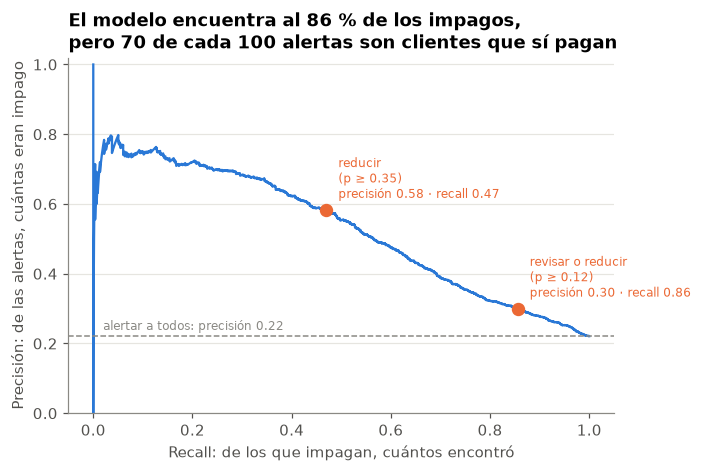

In [6]:
# Curva precisión-recall, con los dos umbrales marcados.
prec, rec, umb = precision_recall_curve(y_ev, p)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(rec, prec, color=AZUL)
ax.axhline(y_ev.mean(), color=GRIS, ls="--", lw=1)
ax.annotate(f"alertar a todos: precisión {y_ev.mean():.2f}", (0.02, y_ev.mean()), xytext=(0, 4),
            textcoords="offset points", fontsize=8, color=GRIS)
for t, etiqueta in [(t1, "revisar o reducir\n(p ≥ 0.12)"), (t2, "reducir\n(p ≥ 0.35)")]:
    i = np.searchsorted(umb, t)
    ax.scatter([rec[i]], [prec[i]], color=NARANJA, zorder=3, s=60)
    ax.annotate(f"{etiqueta}\nprecisión {prec[i]:.2f} · recall {rec[i]:.2f}", (rec[i], prec[i]),
                xytext=(8, 8), textcoords="offset points", fontsize=8, color=NARANJA)
ax.set_xlabel("Recall: de los que impagan, cuántos encontró")
ax.set_ylabel("Precisión: de las alertas, cuántas eran impago")
ax.set_ylim(0, 1.02)
i1 = np.searchsorted(umb, t1)
ax.set_title(f"El modelo encuentra al {100 * rec[i1]:.0f} % de los impagos,\npero {100 * (1 - prec[i1]):.0f} de cada 100 alertas son clientes que sí pagan")
guardar(fig, "f12_precision_recall")
plt.show()

## 4. ¿Dice la verdad? Calibración en los datos de evaluación

Los umbrales suponen que cuando el modelo dice 0.30, impaga cerca del 30 %. En el notebook 02 se
comprobó con simulacros. Aquí se comprueba con clientes que el modelo nunca vio.

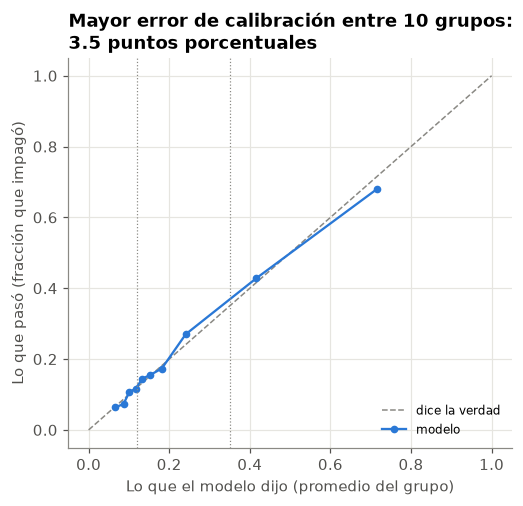

=== PRUEBA ===


,el modelo dijo,impagó,diferencia
0,0.066,0.063,-0.002
1,0.087,0.073,-0.013
2,0.101,0.107,0.006
3,0.117,0.117,0.000
4,0.134,0.145,0.011
5,0.152,0.155,0.003
6,0.182,0.173,-0.008
7,0.241,0.270,0.029
8,0.416,0.428,0.012
9,0.715,0.680,-0.035


In [7]:
real, dicho = calibration_curve(y_ev, p, n_bins=10, strategy="quantile")
cal = pd.DataFrame({"el modelo dijo": dicho, "impagó": real, "diferencia": real - dicho})

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="dice la verdad")
ax.plot(dicho, real, marker="o", ms=4, color=AZUL, label="modelo")
for t in (t1, t2):
    ax.axvline(t, color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("Lo que el modelo dijo (promedio del grupo)")
ax.set_ylabel("Lo que pasó (fracción que impagó)")
ax.set_title(f"Mayor error de calibración entre 10 grupos:\n{100 * cal['diferencia'].abs().max():.1f} puntos porcentuales")
ax.grid(axis="x"); ax.legend(frameon=False, fontsize=8)
guardar(fig, "f13_calibracion_prueba")
plt.show()
print(f"=== {NOMBRE} ===")
cal

## 5. Dónde falla el modelo y con quién

El costo promedio esconde que el modelo no se equivoca igual con todos. Para cada grupo se mira:

- **costo:** lo que le cuesta al banco cada cliente de ese grupo.
- **escapes:** de los que impagan, a cuántos se les mantuvo el límite (el error más caro: 5).
- **castigo injusto:** de los que pagan, a cuántos se les redujo el límite (el error que sufre el cliente).
- **dijo − pasó:** probabilidad media menos tasa real. Positivo = el modelo exagera el riesgo del
  grupo; negativo = lo subestima.

`SEX` y `MARRIAGE` no están en el modelo, pero se usan aquí para revisar si igual los trata distinto.

In [8]:
ev = X_ev.assign(y=y_ev.to_numpy(), p=p, accion=accion, costo=costo_cliente)
ev["Sexo"] = ev["SEX"].map(datos.ETIQUETAS["SEX"])
ev["Educación"] = ev["EDUCATION"].map(datos.ETIQUETAS["EDUCATION"])
ev["Estado civil"] = ev["MARRIAGE"].map(datos.ETIQUETAS["MARRIAGE"])
ev["Edad"] = pd.cut(ev["AGE"], [20, 25, 30, 35, 40, 50, 80], labels=["21–25", "26–30", "31–35", "36–40", "41–50", "51+"])
ev["Cuenta"] = np.where(ev["INACTIVO"] == 1, "Sin movimiento", "Con movimiento")
ev["Septiembre"] = np.select([ev["PAY_1"] <= 0, ev["PAY_1"] == 1], ["Sin atraso", "1 mes de atraso"], "2+ meses de atraso")
ev["Límite"] = pd.qcut(ev["LIMIT_BAL"], 4, labels=["más bajo", "medio bajo", "medio alto", "más alto"])


def por_grupo(columna):
    g = ev.groupby(columna, observed=True)
    t = pd.DataFrame({
        "clientes": g.size(),
        "impago real": g["y"].mean(),
        "dijo − pasó": g["p"].mean() - g["y"].mean(),
        "costo": g["costo"].mean(),
        "% a revisión": g["accion"].apply(lambda a: (a == 1).mean()),
        "escapes": g.apply(lambda d: ((d["accion"] == 0) & (d["y"] == 1)).sum() / max((d["y"] == 1).sum(), 1), include_groups=False),
        "castigo injusto": g.apply(lambda d: ((d["accion"] == 2) & (d["y"] == 0)).sum() / max((d["y"] == 0).sum(), 1), include_groups=False),
    })
    t.index = [f"{columna}: {i}" for i in t.index]
    return t


grupos = pd.concat([por_grupo(c) for c in ["Sexo", "Edad", "Educación", "Estado civil", "Cuenta", "Septiembre", "Límite"]])
print(f"=== {NOMBRE} ===   Costo general: {costo_modelo:.3f}")
grupos

=== PRUEBA ===   Costo general: 0.740


,clientes,impago real,dijo − pasó,costo,% a revisión,escapes,castigo injusto
Sexo: Hombre,2402,0.234,-0.005,0.770,0.452,0.134,0.109
Sexo: Mujer,3598,0.213,0.003,0.720,0.455,0.153,0.087
Edad: 21–25,767,0.256,0.013,0.800,0.518,0.077,0.140
Edad: 26–30,1414,0.200,0.001,0.681,0.404,0.180,0.074
Edad: 31–35,1078,0.192,0.007,0.685,0.405,0.184,0.091
Edad: 36–40,1027,0.228,-0.008,0.736,0.445,0.132,0.083
Edad: 41–50,1243,0.235,-0.012,0.794,0.488,0.154,0.097
Edad: 51+,471,0.244,0.008,0.809,0.541,0.104,0.129
Educación: Otros,82,0.061,0.042,0.267,0.098,0.400,0.052
Educación: Posgrado,2130,0.190,0.002,0.654,0.425,0.160,0.066


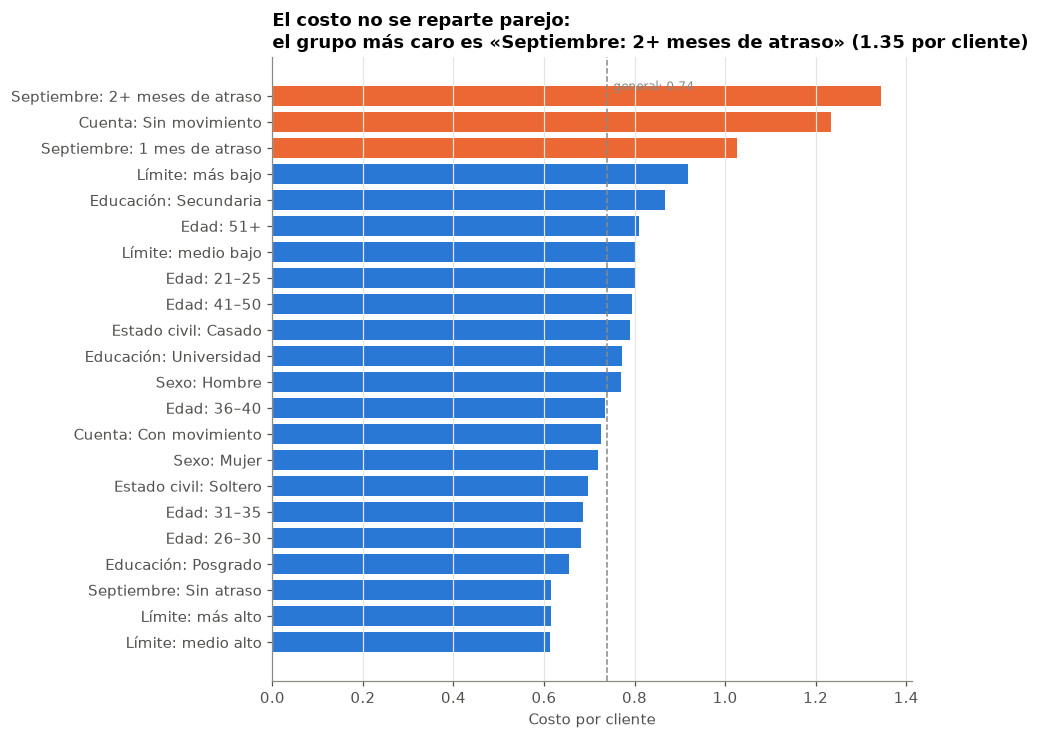

In [9]:
# Los grupos ordenados por costo: dónde le sale más caro al banco equivocarse.
orden = grupos[grupos["clientes"] >= 100].sort_values("costo")
fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(orden) + 1.2))
ax.barh(orden.index, orden["costo"], color=[NARANJA if c > costo_modelo * 1.25 else AZUL for c in orden["costo"]])
ax.axvline(costo_modelo, color=GRIS, ls="--", lw=1)
ax.annotate(f"general: {costo_modelo:.2f}", (costo_modelo, len(orden) - 0.4), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color=GRIS, va="top")
ax.set_xlabel("Costo por cliente")
peor = orden.index[-1]
ax.set_title(f"El costo no se reparte parejo:\nel grupo más caro es «{peor}» ({orden['costo'].iloc[-1]:.2f} por cliente)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
guardar(fig, "f14_costo_por_grupo")
plt.show()

### 5.1 El error más caro: impagos a los que se les mantuvo el límite

¿En qué se diferencian los impagos que el modelo dejó pasar de los que sí alertó?

In [10]:
imp = ev[ev["y"] == 1].copy()
imp["grupo"] = np.where(imp["accion"] == 0, "se escaparon (Mantener)", "alertados (Revisar o Reducir)")
perfil = imp.groupby("grupo").agg(
    clientes=("y", "size"),
    prob_media=("p", "mean"),
    sin_atraso_en_septiembre=("PAY_1", lambda s: (s <= 0).mean()),
    cero_meses_con_atraso=("MESES_ATRASO", lambda s: (s == 0).mean()),
    limite_mediano=("LIMIT_BAL", "median"),
    uso_linea_mediano=("USO_LINEA", "median"),
    pago_septiembre_mediano=("PAY_AMT1", "median"),
).T
print(f"=== {NOMBRE} ===")
perfil

=== PRUEBA ===


grupo,alertados (Revisar o Reducir),se escaparon (Mantener)
clientes,"1,135.000",192.000
prob_media,0.434,0.093
sin_atraso_en_septiembre,0.419,0.995
cero_meses_con_atraso,0.279,0.974
limite_mediano,"80,000.000","220,000.000"
uso_linea_mediano,0.508,0.263
pago_septiembre_mediano,"1,500.000","3,846.000"


### 5.2 Qué mira el modelo

Los pesos de la logística, con las columnas en la misma escala. Peso positivo sube la probabilidad de
impago; negativo la baja. Dos advertencias que ya dejó el EDA: los meses de facturas repiten
información, así que sus pesos **no** se leen uno por uno; y un peso es una **asociación**, no una causa.

Otra advertencia: `PAY_*` y `EDUCATION` entran como categorías, así que cada peso se lee **contra el
resto de los códigos de esa misma columna**, no solo. Un peso negativo en `PAY_1_1` no dice que un mes
de atraso proteja: está compartiendo el efecto con `ATRASO_ULTIMO`, que vale 1 en ese mismo caso. Lo
que se lee con seguridad es el conjunto: el atraso de septiembre es lo que más mueve al modelo.

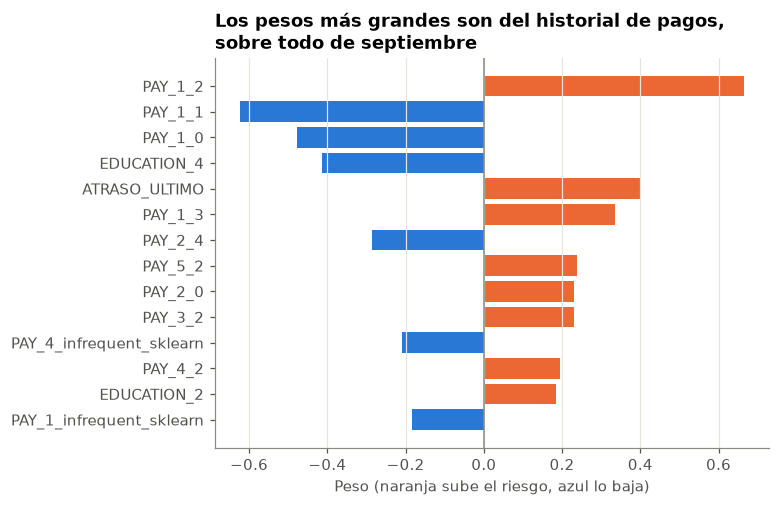

Punto de partida (b): -1.613 · columnas después de preparar: 68


In [11]:
nombres = modelo[0].get_feature_names_out()
pesos = pd.Series(modelo[-1].coef_[0], index=[n.split("__", 1)[1] for n in nombres])
top = pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(14).iloc[::-1]

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.barh(top.index, top.values, color=[NARANJA if v > 0 else AZUL for v in top.values])
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlabel("Peso (naranja sube el riesgo, azul lo baja)")
ax.set_title("Los pesos más grandes son del historial de pagos,\nsobre todo de septiembre")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
guardar(fig, "f15_pesos_logistica")
plt.show()
print("Punto de partida (b):", round(float(modelo[-1].intercept_[0]), 3), "· columnas después de preparar:", len(pesos))

### 5.3 ¿Y si nuestros costos están mal?

El supuesto más discutible es que un impago no detectado cuesta 5 veces lo que cuesta castigar a un
buen cliente. Se recalculan los umbrales para otras razones y se vuelve a medir **con el mismo
modelo** (las probabilidades no cambian; cambia qué se hace con ellas).

In [12]:
filas = []
for razon in [2, 3, 5, 8, 10]:
    mr = costos.matriz_costos(c_impago=razon)
    a, b = costos.umbrales_teoricos(mr)
    c_mod = costos.costo_politica(y_ev, p, a, b, mr)
    c_vara = min(costos.costo_politica_trivial(y_ev, i, mr) for i in range(3))
    acc = costos.asignar_acciones(p, a, b)
    filas.append({"razón impago : castigo": f"{razon} : 1", "t1": a, "t2": b, "costo modelo": c_mod,
                  "vara": c_vara, "ahorro": 1 - c_mod / c_vara, "% a revisión": (acc == 1).mean()})
print(f"=== {NOMBRE} ===")
pd.DataFrame(filas).set_index("razón impago : castigo")

=== PRUEBA ===


,t1,t2,costo modelo,vara,ahorro,% a revisión
razón impago : castigo,,,,,,
2 : 1,0.300,0.500,0.365,0.442,0.176,0.083
3 : 1,0.200,0.437,0.505,0.632,0.201,0.167
5 : 1,0.120,0.350,0.740,0.853,0.133,0.454
8 : 1,0.075,0.269,1.032,1.185,0.129,0.701
10 : 1,0.060,0.233,1.208,1.406,0.140,0.721


### 5.4 La revisión manual: el cuello de botella

Con los umbrales teóricos, una parte grande de los clientes va a un analista. Si el banco no tiene
esa capacidad, la alternativa es subir `t1` (mantener a más gente). Esto muestra cuánto cuesta cada
opción. **Es un análisis de sensibilidad, no una nueva elección de umbral:** el umbral reportado
sigue siendo 0.12.

In [13]:
filas = []
for a in [0.12, 0.15, 0.20, 0.25, 0.30]:
    acc = costos.asignar_acciones(p, a, t2)
    filas.append({"t1": a, "% a revisión": (acc == 1).mean(), "costo": costos.costo_politica(y_ev, p, a, t2),
                  "escapes": ((acc == 0) & (y_ev == 1)).sum() / (y_ev == 1).sum()})
print(f"=== {NOMBRE} ===   vara: {vara:.3f}")
pd.DataFrame(filas).set_index("t1")

=== PRUEBA ===   vara: 0.853


,% a revisión,costo,escapes
t1,,,
0.120,0.454,0.740,0.145
0.150,0.282,0.749,0.254
0.200,0.125,0.769,0.375
0.250,0.057,0.791,0.454
0.300,0.023,0.804,0.495


## 6. Lectura de los resultados

Estos son los números de la corrida del examen: modelo entrenado con 24,000 clientes y evaluado una
sola vez en los 6,000 de `test.csv`, con 1,327 impagos.

**El número.**

- El modelo cuesta **0.740 por cliente**, con IC 95 % de 0.712 a 0.767.
- La vara, revisar a todos, cuesta 0.853 y queda **fuera** del intervalo. El ahorro es de **13.3 %**,
  con IC 95 % de 11.5 % a 15.1 %. Con un modelo perfecto el costo sería 0.332.
- Los simulacros prometían 0.725. El examen salió 0.015 más alto, pero 0.725 cae dentro del
  intervalo, así que esa diferencia no se distingue del ruido de la muestra. Una razón probable, que
  no se probó: las perillas y las columnas se eligieron mirando esos mismos simulacros, y eso los
  vuelve un poco optimistas. **El número que se reporta es 0.740, no 0.725.**
- AUC 0.765 en el examen contra 0.780 en los simulacros. Probabilidad media 0.221, igual que la tasa
  real.

**Qué decidió el modelo.**

| Acción | Clientes | Impagó | % del costo |
|---|---|---|---|
| Mantener | 2,206 | 8.7 % | 21.6 % |
| Revisar | 2,724 | 18.8 % | 47.2 % |
| Reducir | 1,070 | 58.2 % | 31.1 % |

La tasa de impago sube de grupo en grupo, así que el modelo ordena como se esperaba. Con Revisar o
Reducir se alerta a 3,794 clientes y se atrapa el 86 % de los impagos, con precisión de 0.30. Solo
con Reducir se atrapa el 47 %, con precisión de 0.58.

**Los dos errores.**

- **Se escapan 192 de 1,327 impagos, el 14.5 %.** Casi todos tienen septiembre sin atraso
  y casi ningún mes atrasado. Tienen límite mediano de 220,000, contra 80,000 de los alertados,
  y pagaron una mediana de 3,846 en septiembre. Con estas columnas se ven como buenos pagadores. Es
  un límite del modelo y de los datos, y está declarado.
- **Se reduce el límite a 447 de 4,673 buenos pagadores, el 9.6 %.** Es lo que paga el cliente por
  que el banco no se arriesgue.

**¿Dice la verdad?** En el examen, la probabilidad que dio el modelo se acerca a lo que pasó en
casi todos los deciles. Las diferencias más grandes son 0.029 en el decil 8 y 0.035 en el último,
donde el modelo dijo 0.715 y pasó 0.680, así que exagera un poco el riesgo de los más riesgosos.
Cada decil tiene 600 clientes, y con ese tamaño una diferencia de 0.02 todavía puede ser ruido. Los
umbrales 0.12 y 0.35 siguen en la zona donde el modelo está bien calibrado.

**Por grupos.**

- **Sexo.** El modelo no usa `SEX`, y aun así se calibra igual con hombres y mujeres: la diferencia
  entre lo que dijo y lo que pasó es -0.005 y +0.003. El costo es mayor en hombres, 0.770 contra
  0.720, porque impagan más, 23.4 % contra 21.3 %. Entre los que sí pagan, a los hombres se les
  reduce el límite un poco más, 10.9 % contra 8.7 %. Es una brecha chica que no se corrigió.
- **Edad.** A los de 21 a 25 y a los de 51 en adelante se les manda a revisión más seguido, 52 % y
  54 %, y sufren más castigo injusto, 14 % y 13 %, que a los de edad media. La edad está en el modelo.
- **Historial.** El costo va de 0.615 con septiembre sin atraso a 1.027 con un mes y 1.345 con dos o
  más. Es donde el banco pierde más y donde el modelo más detecta.
- **Grupos chicos.** Educación Otros, 82 clientes, y Estado civil Otros, 75, son muy chicos para
  leer sus números.

**Qué mira el modelo.** Los pesos más grandes son del estado de pago de septiembre (figura f15).
Los pesos de `PAY_1_1` y `PAY_1_0` salen negativos por la advertencia de la sección 5.2, no porque
el atraso proteja.

**Si los costos estuvieran mal.** Con razones de 2 a 1 hasta 10 a 1 el modelo siempre le gana a
la vara, con ahorros entre 12.9 % y 20.1 %. A 5 a 1, el supuesto del trabajo, el ahorro es 13.3 %.

**La revisión manual.** Con los umbrales teóricos va a revisión el 45.4 % de los clientes. Si el
banco no tiene capacidad y sube `t1` a 0.20, solo va el 12.5 %, el costo es 0.769 y sigue por debajo
de la vara, pero los escapes suben de 14.5 % a 37.5 %. Es una decisión del banco, no de este modelo.

**Qué no se hizo después de ver esto.** No se movió ningún umbral ni se cambió el modelo.

## 7. Plan de despliegue

**Cómo se usaría.** Una vez al mes, al cerrar la facturación:

1. Se toman, de cada cliente, las mismas columnas que usa el modelo: límite, edad, educación y los
   seis meses de estado de pago, factura y pago.
2. El modelo devuelve una probabilidad de impago para el mes siguiente.
3. La probabilidad se convierte en una acción con los dos umbrales: mantener, revisar o reducir.
4. **El modelo no reduce límites solo.** "Reducir" es una recomendación con su explicación (qué
   columnas subieron el riesgo de ese cliente); la decisión la firma una persona. "Revisar" va a la
   cola del analista ordenada de mayor a menor probabilidad, para que si no alcanza el tiempo se
   revisen primero los casos más riesgosos.

**Antes de encenderlo.** Correrlo un par de meses **en sombra**: el modelo recomienda, el banco
sigue decidiendo como siempre, y se compara. Así se mide el costo real sin arriesgar clientes.

**Qué se monitorea, cada mes:**

| Qué | Cómo | Señal de alarma |
|---|---|---|
| Que siga diciendo la verdad | Probabilidad media contra tasa de impago observada, en total y por decil | Diferencia mayor a unos pocos puntos de forma sostenida |
| Que los clientes sigan pareciéndose | Distribución de `PAY_1`, uso de la línea y límite contra la del entrenamiento | Cambios grandes (por ejemplo, una crisis sube los atrasos de golpe) |
| Carga de revisión | % de clientes que cae entre los umbrales | Más de lo que el equipo puede revisar |
| Costo real | La matriz de 3 acciones con lo que pasó de verdad | Costo por cliente cerca de la vara |
| Trato por grupo | Escapes y castigo injusto por sexo, edad y educación | Brechas que crecen |
| Los supuestos de costo | Cuánto detecta el analista de verdad, cuánta pérdida queda al reducir | Valores lejos de 50 % y 30 % |

**Cuándo se reentrena.** Cuando la calibración se rompa, o al menos una vez al año. Y con una
advertencia: una vez que el banco actúa con el modelo, los datos nuevos ya no son limpios. Si a un
cliente se le reduce el límite y no impaga, no se sabe si fue por la reducción o porque igual iba a
pagar. Conviene dejar un grupo pequeño de control sin intervenir para poder seguir midiendo.

## 8. Lo que NO se puede concluir de este trabajo

1. **No vale para otro banco, otro país ni hoy.** Son clientes de un banco de Taiwán, de abril a
   septiembre de 2005. Las probabilidades describen a esos clientes.
2. **El "ahorro" no es dinero.** Está en unidades de cinco supuestos nuestros (5, 1, 0.3, 50 %, 30 %).
   Ninguno es una cifra del banco. Con otros costos cambian los umbrales y el ahorro (sección 5.3).
3. **No se probó que intervenir funcione.** Se predice quién impaga; no se sabe si reducirle el
   límite a alguien evita la pérdida, la empeora o hace que se vaya. Predecir no es intervenir.
4. **Un solo mes.** Se predice octubre de 2005 con seis meses de historia. No se sabe si el modelo
   aguanta otro mes, otra temporada o una crisis.
5. **Los pesos no son causas.** Que el atraso en septiembre tenga el peso más grande dice que se
   asocia con el impago, no que lo provoque.
6. **No se garantiza un trato justo.** Se quitaron `SEX` y `MARRIAGE`, pero edad y educación siguen
   en el modelo y otras columnas pueden cargar la misma información. Solo se midieron las brechas
   de la sección 5; no se corrigieron.
7. **Hay datos que no se entienden.** Los códigos -2 y 0 de `PAY_*` no están documentados, el código
   1 casi solo existe en septiembre, y las cuentas sin movimiento impagan mucho sin que se sepa por
   qué. El modelo usa esas columnas tal como vienen.
8. **Solo clientes que ya tienen tarjeta.** El modelo no dice nada sobre a quién darle una tarjeta
   nueva: el banco ya filtró a quién se la dio.
9. **No se sabe si el banco puede revisar a tantos.** La capacidad de los analistas no está en los datos.